# Oral condition classifier (6 classes)

**IT2226 AI Innovator and Deep Learning Project: Dental Health Awareness and Affordability in Singapore**

This notebook trains and evaluates the image classifier that closes the brief's **detection gap**. It takes an intraoral photo and returns probabilities for the six classes in [`shared/conditions.yaml`](../../../../shared/conditions.yaml): calculus, caries, hypodontia, mouth ulcer, normal and tooth discoloration. The saved checkpoint (`models/classifier/weights/Daniel/best.pt`) feeds the cost calculator and the agent.

It uses **only the Kaggle oral image dataset** (`data/raw/kaggle_oral/`) and compares a range of ImageNet-pretrained backbones (ConvNeXt Tiny/Small/Base, EfficientNet, ResNet, RegNet, MobileNet, Swin and ViT) under the same data split and training recipe.

> **Scope.** This is a *screening and education aid*. It does not diagnose, and its output must always be presented with a recommendation to see a dentist. The model cannot see gum disease (not a labelled class), so a "normal" result never means "healthy gums".

### Brief data issues and how this notebook handles them

| Issue (brief §4, plus what we found) | What this notebook does | Section |
|---|---|---|
| Uneven classes (Caries 219 vs Calculus 1,296) | Measures the *real* imbalance after de-duplication; class- and group-balanced sampling; macro-F1 / balanced accuracy as headline metrics | 3, 5, 7 |
| **Found:** Kaggle ships with pre-augmented copies and duplicates (rotated, sheared and recoloured copies; byte-identical files) | Exact + perceptual (pHash) + CNN-embedding near-duplicate grouping; **group-aware** splits so copies never straddle train/test; test on one image per group | 3, 4 |
| One label per image, even when a mouth shows several conditions | Detects identical photos filed under different classes, keeps them out of val/test; reports top-2 probabilities rather than a hard label | 3, 8 |
| Image quality, lighting and framing vary | Quality EDA per class (resolution, brightness, sharpness); strong photometric + JPEG/blur augmentation; robustness test under degraded photos; abstention threshold | 2, 5, 7 |
| **Found:** the Normal class comes from a different camera source (phone photos, ~10x the resolution) | Every image is resized into a common cache; JPEG/blur augmentation; explicit resolution-shortcut test | 2, 7 |
| Images are not from Singapore patients | Cannot be measured with Kaggle data alone. Documented as a limitation; a Singapore validation set is needed before real use | 10 |
| Gum disease is not a labelled class | Cannot be fixed with this data; documented and passed to the app via the checkpoint notes | 10 |

### Data

| Folder | What it contains | Used for |
|---|---|---|
| `kaggle_oral/` | The brief's core dataset: 4,375 photos, 6 single-label classes | Train / val / test (group-aware split) |

Other folders under `data/raw/` are not read by this notebook. Run `python models/classifier/notebooks/Daniel/setup.py kaggle_oral` first to download the Kaggle data (needs Kaggle credentials).

## 0. Setup

In [39]:
# Install the notebook's dependencies into THIS kernel's Python environment.
# Safe to re-run: only missing packages are installed. Restart the kernel afterwards if anything was installed.
import importlib.util, subprocess, sys

PACKAGES = {  # import name -> pip package
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "PIL": "pillow", "cv2": "opencv-python", "yaml": "pyyaml",
    "tqdm": "tqdm", "IPython": "ipython", "kagglehub": "kagglehub",
}
# PyTorch comes from its own index so the GPU build is installed (plain `pip install torch` gives the CPU build on Windows).
# CUDA 12.8 wheels support RTX 50-series cards; use "https://download.pytorch.org/whl/cpu" on a machine without an NVIDIA GPU.
TORCH_INDEX = "https://download.pytorch.org/whl/cu128"


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


installed = []
missing = [pkg for mod, pkg in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", " ".join(missing))
    pip_install(*missing); installed += missing
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    print("installing torch + torchvision from", TORCH_INDEX)
    pip_install("torch", "torchvision", "--index-url", TORCH_INDEX); installed += ["torch", "torchvision"]

import torch, torchvision
tv_version = tuple(int(x) for x in torchvision.__version__.split("+")[0].split(".")[:2])
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"CUDA available: {torch.cuda.is_available()}")
if tv_version < (0, 20):
    print("WARNING: torchvision >= 0.20 is needed (v2.JPEG augmentation). Upgrade with:\n"
          f"  {sys.executable} -m pip install -U torch torchvision --index-url {TORCH_INDEX}")
if not torch.cuda.is_available():
    print("NOTE: no GPU visible. The notebook still runs on CPU, but training will be very slow.")
if installed:
    print("Installed packages: restart the kernel, then run the notebook from the next cell.")


python 3.13.14 | torch 2.15.0+cu134 | torchvision 0.29.2+cu134 | CUDA available: True


In [40]:
import os, io, json, time, math, copy, random, hashlib, warnings, datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import cv2
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
from scipy.fft import dctn
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision as tv
from torchvision.transforms import v2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_recall_fscore_support)
from tqdm import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def find_repo_root():
    # Look for shared/conditions.yaml, in order:
    #  1. upwards from $DLWIU_ROOT (manual override), the kernel's working directory and the notebook's own folder
    #     (VS Code exposes it as __vsc_ipynb_file__);
    #  2. the notebook's path re-rooted at this machine's home folder. On a remote Jupyter server VS Code sends the
    #     *client's* path (e.g. C:\Users\me\OneDrive\Documents\School\...), so we also try ~/Documents/School/...,
    #     ~/OneDrive/Documents/School/..., and every other tail of that path under the server's home;
    #  3. up to two levels below the kernel's working directory (e.g. C:\Jupyter\Deep-Learning-WIU).
    def search_up(start):
        for p in [start, *start.parents]:
            if (p / "shared" / "conditions.yaml").exists():
                return p.resolve()
        return None

    starts = []
    if os.environ.get("DLWIU_ROOT"):
        starts.append(Path(os.environ["DLWIU_ROOT"]))
    starts.append(Path.cwd())
    nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else None
    if nb_dir is not None:
        starts.append(nb_dir)
    for s in starts:
        if (root := search_up(s)) is not None:
            return root
    if nb_dir is not None:
        parts = nb_dir.parts[1:]                       # drop the drive / anchor
        for base in [Path.home(), Path.home() / "OneDrive"]:
            for i in range(len(parts)):
                cand = base.joinpath(*parts[i:])
                if (root := search_up(cand)) is not None:      # cand need not exist (older clone)
                    return root
    for pattern in ["*/shared/conditions.yaml", "*/*/shared/conditions.yaml"]:
        hits = sorted(Path.cwd().glob(pattern))
        if hits:
            return hits[0].parents[1].resolve()
    raise FileNotFoundError(
        f"Could not find the Deep-Learning-WIU repo (looked upwards from {[str(s) for s in starts]}, under {Path.home()} and two levels "
        f"below {Path.cwd()}). If this kernel runs on a remote Jupyter server, the repo and data/raw/kaggle_oral must "
        "exist on THAT machine. Clone it there, or point to it before this cell: "
        "os.environ['DLWIU_ROOT'] = r'C:\\path\\to\\Deep-Learning-WIU'")


ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"
CACHE_DIR = ROOT / "data" / "interim" / "Daniel" / "classifier_cache"   # resized copies of every image (gitignored)
PROC = ROOT / "data" / "processed" / "classifier" / "Daniel"  # feature caches (gitignored)
MANIFESTS = ROOT / "manifests" / "Daniel"                    # split CSV (committed: reproducible without data)
WEIGHTS = ROOT / "models" / "classifier" / "weights" / "Daniel"   # checkpoints (gitignored)
RESULTS = ROOT / "models" / "classifier" / "results" / "Daniel"   # metrics + figures for the report
FIGS = RESULTS / "figures"
RUNS_DIR = RESULTS / "runs"                                        # per-run history + summary (gitignored cache)
for d in [CACHE_DIR, PROC, MANIFESTS, WEIGHTS, RESULTS, FIGS, RUNS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,
    cache_max_side=384,          # every image is stored at <=384 px so all sources share a resolution
    img_size=224,
    ablation_backbone="convnext_tiny",   # backbone for the recipe ablation (A baseline vs B full recipe)
    # Backbones trained with the full recipe in section 6.2 (all torchvision, ImageNet-pretrained).
    # Trim this list for a quicker run; see BACKBONES in section 5 for the per-model settings.
    sweep=["convnext_tiny", "convnext_small", "convnext_base",
           "efficientnet_b0", "efficientnet_b3", "efficientnet_v2_s",
           "resnet50", "regnet_y_3_2gf", "densenet121", "mobilenet_v3_large",
           "swin_t", "vit_b_16"],
    epochs=25, patience=6, batch_size=32,
    weight_decay=0.05, warmup_epochs=1,  # the peak learning rate is set per backbone family (BACKBONES)
    dup_phash_max_hamming=6,     # pHash distance <= 6 bits  -> same photo
    dup_cosine_min=0.90,         # CNN embedding cosine >= 0.90 -> same photo (rotated / sheared / recoloured)
    min_side_px=64,              # drop thumbnails smaller than this
    test_frac=0.15, val_frac=0.15,
    tie_margin=0.01,             # runs within this val score of the best count as tied -> fastest on CPU wins
    target_selective_accuracy=0.95,    # abstain below the confidence that reaches this accuracy on val
    min_abstain_conf=0.50,             # ...and never answer with a top probability below this
    # A run that already has a checkpoint (weights/Daniel/exp_<name>.pt) is never retrained; its saved results are
    # reused. List run names here to retrain them anyway, e.g. ["B_resnet50"], or "all" to retrain everything.
    retrain=[],
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16


def seed_everything(seed=CFG["seed"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


seed_everything()
torch.backends.cudnn.benchmark = True
print("repo root:", ROOT)
print("torch", torch.__version__, "| torchvision", tv.__version__, "| device:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

repo root: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU
torch 2.15.0+cu134 | torchvision 0.29.2+cu134 | device: cuda NVIDIA GeForce RTX 5070 Ti


In [41]:
# Class IDs come from the shared single source of truth, never re-numbered here.
conditions = yaml.safe_load(open(ROOT / "shared" / "conditions.yaml"))["conditions"]
conditions = sorted(conditions, key=lambda c: c["id"])
assert [c["id"] for c in conditions] == list(range(len(conditions))), "class ids must be 0..N-1"
CLASSES = [c["name"] for c in conditions]
DISPLAY = {c["name"]: c["display_name"] for c in conditions}
SRC2NAME = {c["source_label"].lower(): c["name"] for c in conditions}
CLS2ID = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
CARIES = CLS2ID["caries"]
pd.DataFrame(conditions)[["id", "name", "display_name", "source_label"]]

,id,name,display_name,source_label
0,0,calculus,Calculus (tartar),Calculus
1,1,caries,Dental caries,caries
2,2,hypodontia,Hypodontia,Hypodontia
3,3,mouth_ulcer,Mouth ulcer,Mouth ulcer
4,4,normal,No visible condition,Normal
5,5,tooth_discoloration,Tooth discoloration,tooth discoloration


## 1. Index the Kaggle dataset

Each image is read once and, in the same pass:
- an MD5 of the raw bytes is computed (exact duplicates);
- the image is EXIF-rotated, downsized to at most 384 px and cached as JPEG under `data/interim/Daniel/classifier_cache/<md5>.jpg`. Training reads only this cache, so a 12 MP phone photo and a 600 px web image reach the model at the same resolution;
- a 64-bit perceptual hash (DCT pHash), brightness and sharpness (variance of the Laplacian) are measured.

In [42]:
def phash_bits(im):
    a = np.asarray(im.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    d = dctn(a, norm="ortho")[:8, :8].flatten()
    return (d > np.median(d[1:])).astype(np.uint8)


def load_rgb(src, max_side=None):
    # Open, honour EXIF orientation, convert to RGB and optionally downsize (fast JPEG draft decode).
    im = Image.open(src)
    if max_side and im.format == "JPEG":
        im.draft("RGB", (max_side, max_side))
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side), Image.LANCZOS)
    return im


def index_images(df, desc):
    # Adds md5, original size, cache path, pHash and simple quality stats. Cached images are reused.
    recs, bits = [], []
    for p in tqdm(df["path"], desc=desc):
        r = dict(ok=False, md5=None, orig_w=np.nan, orig_h=np.nan, cache=None, brightness=np.nan, sharpness=np.nan)
        h = np.zeros(64, np.uint8)
        try:
            b = Path(p).read_bytes()
            r["md5"] = hashlib.md5(b).hexdigest()
            with Image.open(io.BytesIO(b)) as im0:
                w, hgt = im0.size
                if im0.getexif().get(0x0112, 1) in (5, 6, 7, 8):   # EXIF says rotated 90 degrees
                    w, hgt = hgt, w
            r["orig_w"], r["orig_h"] = w, hgt
            cpath = CACHE_DIR / f"{r['md5']}.jpg"
            if not cpath.exists():
                load_rgb(io.BytesIO(b), CFG["cache_max_side"]).save(cpath, quality=95)
            im = Image.open(cpath).convert("RGB")
            gray = np.asarray(im.convert("L"))
            r.update(cache=str(cpath), ok=min(w, hgt) >= CFG["min_side_px"],
                     brightness=float(gray.mean()), sharpness=float(cv2.Laplacian(gray, cv2.CV_64F).var()))
            h = phash_bits(im)
        except Exception as e:  # unreadable / truncated file
            print("unreadable:", p, e)
        recs.append(r); bits.append(h)
    out = pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
    return out, np.stack(bits)

In [43]:
kaggle_dirs = list(RAW.glob("kaggle_oral/**/oral dataset"))
assert kaggle_dirs, "Kaggle data not found: run models/classifier/notebooks/Daniel/setup.py"
KAGGLE_DIR = kaggle_dirs[0]

rows = []
for d in sorted(p for p in KAGGLE_DIR.iterdir() if p.is_dir()):
    for f in sorted(d.iterdir()):
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append(dict(source="kaggle", path=str(f), label=SRC2NAME[d.name.lower()], patient=None))
kag, kag_bits = index_images(pd.DataFrame(rows), "kaggle")
kag["file_ext"] = kag.path.str.extract(r"\.(\w+)$")[0]
kag["megapixels"] = kag.orig_w * kag.orig_h / 1e6
print(f"{len(kag)} files | unreadable: {(kag.md5.isna()).sum()} | smaller than {CFG['min_side_px']} px: {(~kag.ok & kag.md5.notna()).sum()}")
kag.groupby("label").size().rename("images").to_frame().T

kaggle: 100%|██████████| 4375/4375 [00:05<00:00, 794.47it/s] 

4375 files | unreadable: 0 | smaller than 64 px: 99


label,calculus,caries,hypodontia,mouth_ulcer,normal,tooth_discoloration
images,1296,219,1251,265,286,1058


## 2. Exploratory analysis: imbalance, quality and source shortcuts

The brief warns that quality, lighting and framing vary. The question that matters for a classifier is whether they vary **by class**. If they do, the network can learn the camera instead of the condition.

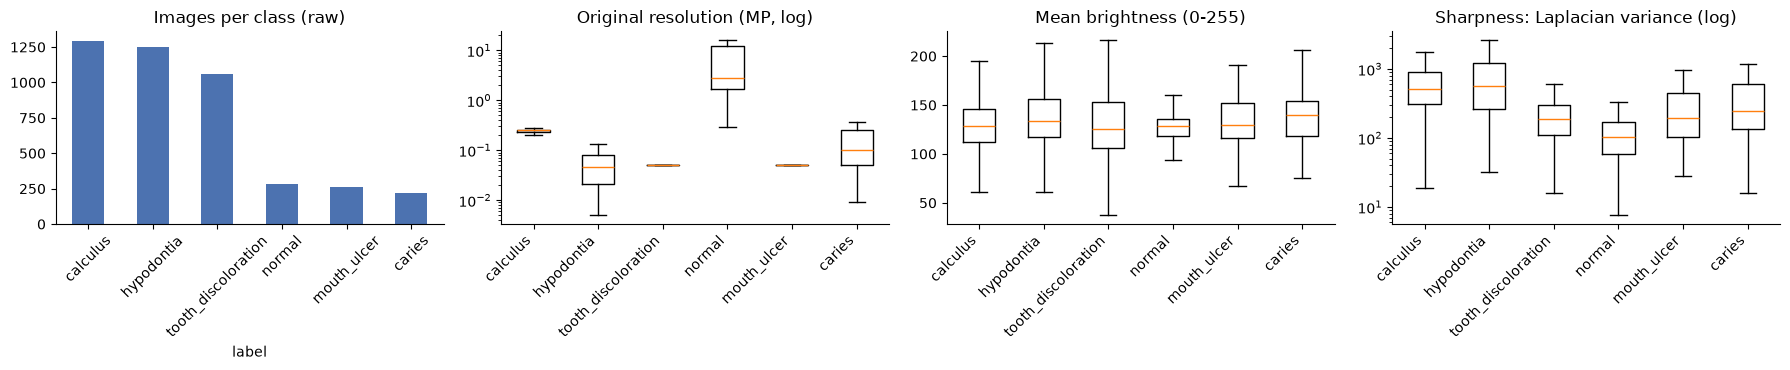

,median_MP,median_brightness,median_sharpness
label,,,
calculus,0.25,128.23,509.88
caries,0.10,139.91,249.77
hypodontia,0.05,133.88,560.73
mouth_ulcer,0.05,130.08,192.79
normal,2.77,128.53,101.92
tooth_discoloration,0.05,125.25,188.36


,JPG,jpeg,jpg
label,,,
calculus,0,0,1296
caries,0,0,219
hypodontia,909,0,342
mouth_ulcer,0,0,265
normal,0,0,286
tooth_discoloration,0,875,183


In [44]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
order = kag.label.value_counts().index
kag.label.value_counts().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Images per class (raw)")
for a, col, title, log in [(ax[1], "megapixels", "Original resolution (MP, log)", True),
                           (ax[2], "brightness", "Mean brightness (0-255)", False),
                           (ax[3], "sharpness", "Sharpness: Laplacian variance (log)", True)]:
    a.boxplot([kag.loc[kag.label == c, col].dropna() for c in order], showfliers=False)
    a.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right"); a.set_title(title)
    if log: a.set_yscale("log")
ax[0].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIGS / "eda_class_quality.png", bbox_inches="tight"); plt.show()

display(kag.groupby("label").agg(median_MP=("megapixels", "median"), median_brightness=("brightness", "median"),
                                 median_sharpness=("sharpness", "median")).round(2))
display(pd.crosstab(kag.label, kag.file_ext).rename_axis(None, axis=1))

**Reading the plots**
- **Normal** images are phone photos at several megapixels; every other class is mostly web-sized (around 0.25 MP). A model given raw resolution, sharpness or JPEG artefacts could separate Normal without looking at teeth. Caching everything at ≤384 px and adding blur/JPEG augmentation removes most of this signal; section 7.2 tests whether any remains.
- **Tooth discoloration** has ~875 `.jpeg` files named `Tooth_Discoloration_0_<n>.jpeg`. This is the naming pattern of Keras `ImageDataGenerator`, so the class was **augmented before it was published**. The duplicate scan below confirms the same for Calculus and Hypodontia.

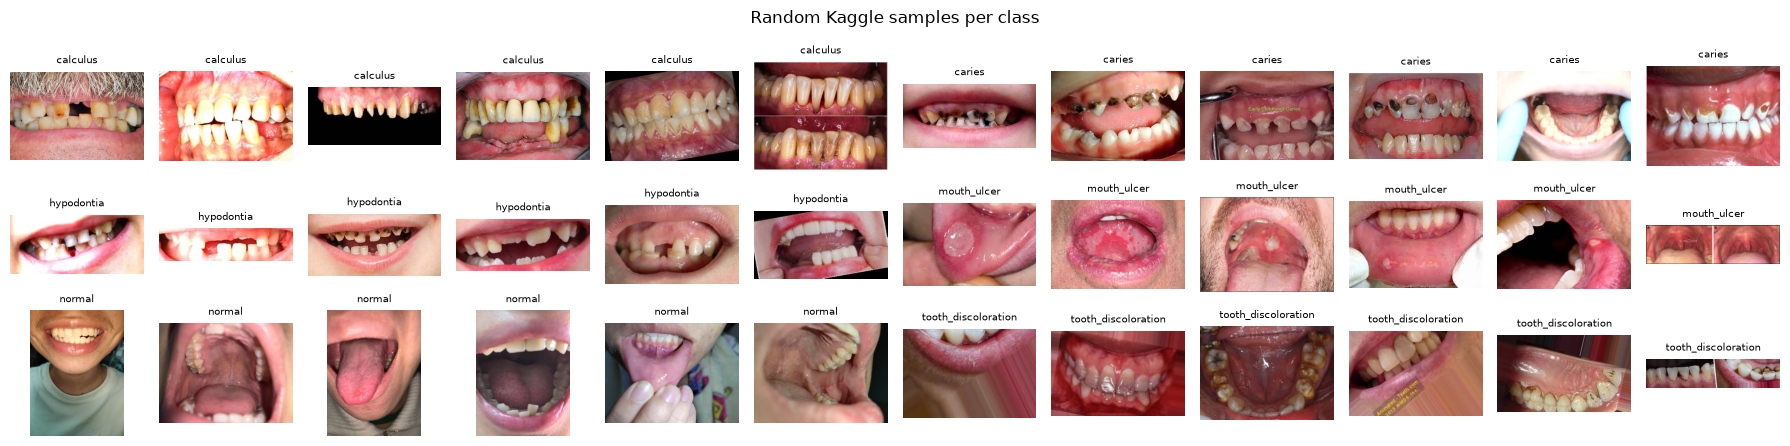

In [45]:
def show_grid(paths, titles=None, ncol=8, size=2.0, suptitle=None):
    n = len(paths); nrow = max(1, math.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for i, a in enumerate(np.atleast_1d(axes).flat):
        a.axis("off")
        if i < n:
            a.imshow(Image.open(paths[i]).convert("RGB"))
            if titles is not None: a.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
samp = kag[kag.ok].groupby("label").sample(n=6, random_state=0)
show_grid(samp.cache.tolist(), samp.label.tolist(), ncol=12, size=1.5, suptitle="Random Kaggle samples per class")

## 3. Duplicate and near-duplicate detection

A random split of this dataset would put augmented copies of the same photo in both train and test, which inflates test accuracy. We build a graph where two images are linked if **any** of the following holds:

1. identical bytes (MD5),
2. pHash Hamming distance ≤ 6 (re-encoded / resized / lightly recoloured copies),
3. cosine similarity ≥ 0.90 between ImageNet EfficientNet-B0 embeddings (rotated, sheared, cropped copies that pHash misses).

The thresholds were picked by inspecting pairs in similarity bands; pairs above 0.90 were almost always the same photo. Over-grouping is safe because it only makes the split stricter. **Connected components** of this graph are "photo groups", and every split below is done by group.

In [46]:
FEAT_CACHE = PROC / "embeddings_effb0.npz"


@torch.no_grad()
def embed_cached(paths, bs=64):
    # L2-normalised EfficientNet-B0 (ImageNet) features, cached on disk by file name (= md5).
    store = {}
    if FEAT_CACHE.exists():
        z = np.load(FEAT_CACHE); store = dict(zip(z["keys"].tolist(), z["emb"]))
    todo = [p for p in dict.fromkeys(paths) if Path(p).stem not in store]
    if todo:
        w = tv.models.EfficientNet_B0_Weights.IMAGENET1K_V1
        m = tv.models.efficientnet_b0(weights=w); m.classifier = nn.Identity(); m = m.to(DEVICE).eval()
        tf = w.transforms()
        for i in tqdm(range(0, len(todo), bs), desc="embedding"):
            chunk = todo[i:i + bs]
            x = torch.stack([tf(Image.open(p).convert("RGB")) for p in chunk]).to(DEVICE)
            for p, e in zip(chunk, F.normalize(m(x), dim=1).cpu().numpy()):
                store[Path(p).stem] = e.astype(np.float32)
        np.savez(FEAT_CACHE, keys=np.array(list(store)), emb=np.stack(list(store.values())))
    return np.stack([store[Path(p).stem] for p in paths])


def hamming(A, B):
    A = A.astype(np.float32); B = B.astype(np.float32)
    return A @ (1 - B).T + (1 - A) @ B.T


def dup_matrix(bits_a, emb_a, bits_b=None, emb_b=None, cos_min=None):
    bits_b = bits_a if bits_b is None else bits_b
    emb_b = emb_a if emb_b is None else emb_b
    cos_min = CFG["dup_cosine_min"] if cos_min is None else cos_min
    return (emb_a @ emb_b.T >= cos_min) | (hamming(bits_a, bits_b) <= CFG["dup_phash_max_hamming"])


okm = kag.ok.values
kag, kag_bits = kag[okm].reset_index(drop=True), kag_bits[okm]
kag_emb = embed_cached(kag.cache.tolist())

exact duplicate files                : 553
byte-identical files in >1 class      : 27 distinct images
photo groups (after near-dup merge)   : 2264 from 4276 files
groups whose copies carry >1 label    : 19 (284 files)
largest group size                    : 51


,files,unique_photos,files_in_conflicting_groups,copies_per_photo,share_raw_%,share_unique_%
label,,,,,,
calculus,1296,252,227,5.14,30.3,11.0
hypodontia,1152,482,18,2.39,26.9,21.1
tooth_discoloration,1058,864,27,1.22,24.7,37.8
normal,286,282,0,1.01,6.7,12.3
mouth_ulcer,265,220,0,1.20,6.2,9.6
caries,219,185,12,1.18,5.1,8.1


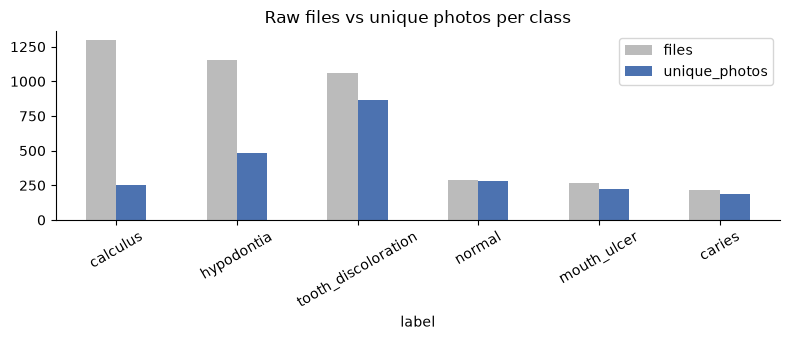

In [47]:
A_kag = dup_matrix(kag_bits, kag_emb)
n_groups, comp = connected_components(csr_matrix(A_kag), directed=False)
kag["group"] = ["k%05d" % c for c in comp]
kag["group_size"] = kag.groupby("group").path.transform("size")
labels_in_group = kag.groupby("group").label.nunique()
kag["label_conflict"] = kag.group.map(labels_in_group) > 1

exact_dup = kag.md5.duplicated(keep="first").sum()
md5_conflict = (kag.groupby("md5").label.nunique() > 1).sum()
print(f"exact duplicate files                : {exact_dup}")
print(f"byte-identical files in >1 class      : {md5_conflict} distinct images")
print(f"photo groups (after near-dup merge)   : {n_groups} from {len(kag)} files")
print(f"groups whose copies carry >1 label    : {(labels_in_group > 1).sum()} ({kag.label_conflict.sum()} files)")
print(f"largest group size                    : {kag.group_size.max()}")

summary = kag.groupby("label").agg(files=("path", "size"), unique_photos=("group", "nunique"),
                                   files_in_conflicting_groups=("label_conflict", "sum"))
summary["copies_per_photo"] = (summary.files / summary.unique_photos).round(2)
summary["share_raw_%"] = (100 * summary.files / summary.files.sum()).round(1)
summary["share_unique_%"] = (100 * summary.unique_photos / summary.unique_photos.sum()).round(1)
display(summary.sort_values("files", ascending=False))

ax = summary.sort_values("files", ascending=False)[["files", "unique_photos"]].plot.bar(figsize=(8, 3.5), color=["#bbbbbb", "#4C72B0"])
ax.set_title("Raw files vs unique photos per class"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIGS / "raw_vs_unique.png", bbox_inches="tight"); plt.show()

**What this changes.** The brief describes the imbalance as Caries 219 vs Calculus 1,296. After de-duplication, **Calculus has only ~255 distinct photos** (about five augmented copies each), and the largest class is really Tooth discoloration. A sampler that balances by file count would still over-weight a handful of Calculus photos, so the sampler in section 5 balances by **class and photo group**.

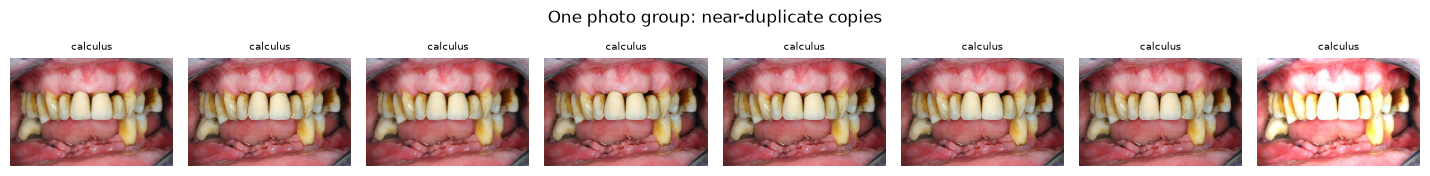

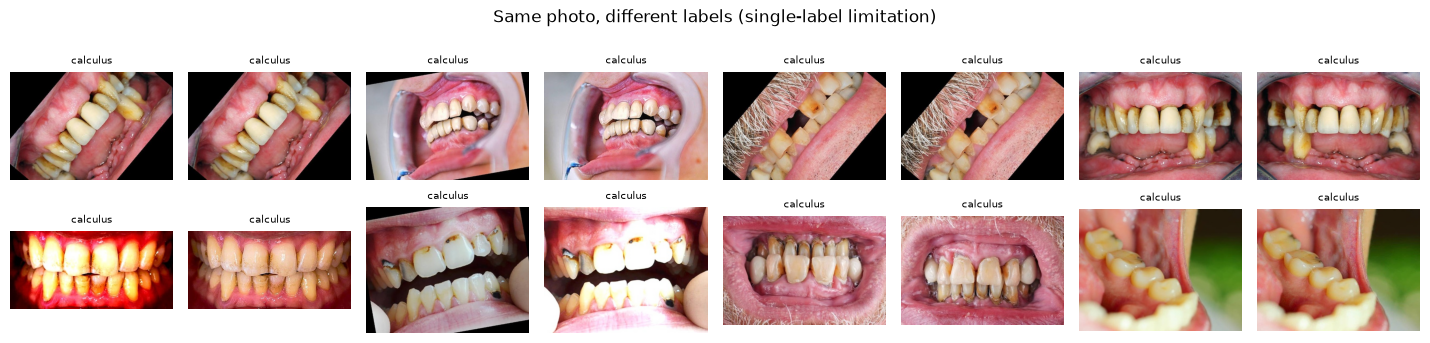

groups
calculus caries hypodontia tooth_discoloration        
True     True   False      False                     8
         False  False      True                      5
                True       False                     4
                           True                      2

In [48]:
# Examples: one multi-copy group, and groups where the same photo carries different labels
big = kag[kag.group == kag.loc[kag.group_size.idxmax(), "group"]].head(8)
show_grid(big.cache.tolist(), big.label.tolist(), ncol=8, size=1.8, suptitle="One photo group: near-duplicate copies")

conf = kag[kag.label_conflict].sort_values("group")
ex = conf.groupby("group").head(2).head(16)
show_grid(ex.cache.tolist(), ex.label.tolist(), ncol=8, size=1.8, suptitle="Same photo, different labels (single-label limitation)")
display(pd.crosstab(conf.group, conf.label).astype(bool).value_counts().rename("groups").to_frame().head(10))

**Label conflicts.** The same photo filed under two classes, usually Calculus with Hypodontia or Tooth discoloration, is the brief's *one label per image* problem in concrete form: the mouth really shows both. These groups go to **training only**, where the model sees both labels and learns to split probability between them. They are never in val/test, where a single "right answer" would be arbitrary. The app should show the **top two** conditions, not only the argmax.

### How much a naive random split would leak

In [49]:
rng = np.random.default_rng(CFG["seed"])
perm = rng.permutation(len(kag)); n_te = int(0.15 * len(kag))
te_idx, tr_idx = perm[:n_te], perm[2 * n_te:]
leak = A_kag[np.ix_(te_idx, tr_idx)].any(1)
print(f"Random 70/15/15 split: {leak.mean():.1%} of test images would have a copy of the same photo in train.")
print(kag.iloc[te_idx].assign(leak=leak).groupby("label").leak.mean().map("{:.0%}".format).to_string())

Random 70/15/15 split: 53.2% of test images would have a copy of the same photo in train.
label
calculus               90%
caries                 16%
hypodontia             69%
mouth_ulcer            27%
normal                  0%
tooth_discoloration    24%


## 4. Group-aware train / val / test split (Kaggle)

- `StratifiedGroupKFold` keeps every photo group in one split while keeping the class mix similar (≈70/15/15).
- Label-conflict groups are forced into train.
- Val and test keep **one representative image per group** (the largest, preferring originals over `.jpeg` augmentation outputs). The other copies of a val/test photo are dropped entirely. Moving them to train would leak.
- The split is written to `manifests/Daniel/classifier_split.csv` (relative paths + MD5), so teammates can rebuild it without committing images.

In [50]:
def _fold_of_size(df, label_col, k, seed):
    # StratifiedGroupKFold can leave a fold nearly empty when one class is rare, so take the fold closest to 1/k.
    folds = list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed).split(df, df[label_col], df["group"]))
    return min(folds, key=lambda f: abs(len(f[1]) - len(df) / k))


def group_split(df, label_col, test_frac, val_frac, seed):
    # Returns a Series of 'train'/'val'/'test' using two rounds of StratifiedGroupKFold.
    split = pd.Series("train", index=df.index)
    k_test = max(2, round(1 / test_frac))
    rest, te = _fold_of_size(df, label_col, k_test, seed)
    split.iloc[te] = "test"
    df_rest = df.iloc[rest]
    k_val = max(2, round((1 - 1 / k_test) / val_frac))
    _, va = _fold_of_size(df_rest, label_col, k_val, seed + 1)
    split.loc[df_rest.index[va]] = "val"
    return split


def pick_representatives(df):
    # One image per group: prefer non-augmented originals, then the largest original resolution.
    key = df.assign(_aug=df.file_ext.str.lower().eq("jpeg").astype(int),
                    _area=-(df.orig_w * df.orig_h))
    keep = key.sort_values(["group", "_aug", "_area"]).groupby("group").head(1).index
    return df.index.isin(keep)


clean = kag[~kag.label_conflict]
kag["split"] = "train"
kag.loc[clean.index, "split"] = group_split(clean, "label", CFG["test_frac"], CFG["val_frac"], CFG["seed"])
kag["eval_rep"] = False
for s in ["val", "test"]:
    m = kag.split == s
    kag.loc[m, "eval_rep"] = pick_representatives(kag[m])
kag["use"] = (kag.split == "train") | kag.eval_rep          # non-representative val/test copies are dropped

# sanity checks: no group straddles splits; no train image near-duplicates a test image
assert kag.groupby("group").split.nunique().max() == 1
tr_m, te_m = (kag.split == "train").values, (kag.split == "test").values
assert not A_kag[np.ix_(te_m, tr_m)].any(), "leak between test and train"

tab = pd.crosstab(kag[kag.use].label, kag[kag.use].split)[["train", "val", "test"]]
tab["train_unique_photos"] = kag[kag.split == "train"].groupby("label").group.nunique()
display(tab)

split,train,val,test,train_unique_photos
label,,,,
calculus,991,33,32,187
caries,160,26,25,134
hypodontia,828,68,69,345
mouth_ulcer,190,31,31,158
normal,204,40,40,202
tooth_discoloration,763,122,124,618


In [51]:
# Persist the split so it is reproducible without sharing images
man = kag[["source", "path", "md5", "label", "group", "split", "eval_rep", "label_conflict", "use"]].copy()
man["path"] = man.path.map(lambda p: os.path.relpath(p, ROOT).replace(os.sep, "/"))
man.to_csv(MANIFESTS / "classifier_split.csv", index=False)
print("wrote", MANIFESTS / "classifier_split.csv", len(man), "rows")

wrote C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\manifests\Daniel\classifier_split.csv 4276 rows


## 5. Training setup

### Backbones compared

All models are torchvision ImageNet-pretrained classifiers whose final linear layer is replaced with a 6-class head, then fully fine-tuned. They cover three design families and a wide range of sizes, so the comparison answers two questions: *which architecture suits ~1,000 unique dental photos*, and *how much accuracy a bigger model buys* compared with what it costs at inference time in the app.

| Family | Models | Why it is in the comparison |
|---|---|---|
| ConvNeXt (modern CNN) | Tiny (28M), Small (50M), Base (89M) | Size scaling within one family: does a bigger ConvNeXt help on a small dataset, or just overfit? |
| EfficientNet | B0 (5M), B3 (12M), V2-S (21M) | Compound-scaled CNNs, strong accuracy per FLOP |
| ResNet / RegNet | ResNet-50 (26M), RegNetY-3.2GF (19M) | Classic transfer-learning baselines |
| DenseNet | DenseNet-121 (8M) | Dense feature reuse; a small, well-established medical-imaging baseline |
| MobileNet | V3-Large (5M) | Phone-class model; the cheapest option for the app |
| Vision transformers | Swin-T (28M), ViT-B/16 (86M) | Attention-based models; known to need more data, so a useful contrast |

The peak learning rate is set per family (AdamW): 1e-4 for ConvNeXt and Swin, 5e-5 for ViT, 3e-4 for EfficientNet/ResNet/RegNet/DenseNet and 5e-4 for MobileNet. These are common fine-tuning defaults for each family. Everything else is identical across runs.

### Training recipe

* **Input.** The whole image is resized to 224×224 (squash, no centre-crop) so lesions near the edge, such as ulcers on the lip, are not cut off.
* **Augmentation (B).** Random resized crops, small rotations, flips, brightness/contrast jitter with a deliberately tiny hue jitter (colour is diagnostic for discoloration and calculus), Gaussian blur and JPEG re-compression to mimic poor phone photos.
* **Balancing (B).** `WeightedRandomSampler` with weight = 1 / (#groups in class × #copies in group): every class is drawn equally often, and within a class every *photo* (not every file) is equally likely.
* **Loss.** Cross-entropy with label smoothing 0.1 (B). The labels are noisy (single-label, multi-condition mouths), so the model should not be pushed to 100% confidence.
* **Optimiser.** AdamW, weight decay 0.05, cosine decay with 1 warm-up epoch, bf16 autocast. Early stopping and checkpoint choice on the **validation score** (below), patience 6.

### Experiments

| ID | Backbone | Sampler | Augmentation | Purpose |
|---|---|---|---|---|
| A | ConvNeXt-Tiny | plain shuffle | flip only | Naive baseline: what imbalance and duplicates do |
| B | every backbone in `CFG["sweep"]` | class + group balanced | strong | Backbone comparison under the full recipe |

**Selection rule (fixed before training).** Patients will upload phone photos, not curated web images, so the validation score is the **mean of macro-F1 on the clean val set and on a "phone-quality" copy of it**. In that copy each image is either downscaled to 160 px, darkened, blurred or heavily JPEG-compressed.
1. The run with the highest validation score is the reference.
2. Every run within **0.01** of it counts as tied (the val set has only ~320 images, so smaller gaps are noise).
3. Among tied runs, the one with the **lowest CPU latency** wins, because the app runs the model on a CPU server.

The test set is used once, after selection.

In [52]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics, shared by every torchvision model
S = CFG["img_size"]

# head = attribute path of the final nn.Linear that is replaced; lr = AdamW peak learning rate for fine-tuning
BACKBONES = {
    "convnext_tiny":      dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "convnext_small":     dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "convnext_base":      dict(family="ConvNeXt",     head="classifier.2", lr=1e-4),
    "efficientnet_b0":    dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "efficientnet_b3":    dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "efficientnet_v2_s":  dict(family="EfficientNet", head="classifier.1", lr=3e-4),
    "resnet50":           dict(family="ResNet",       head="fc",           lr=3e-4),
    "regnet_y_3_2gf":     dict(family="RegNet",       head="fc",           lr=3e-4),
    "densenet121":        dict(family="DenseNet",     head="classifier",   lr=3e-4),
    "densenet169":        dict(family="DenseNet",     head="classifier",   lr=3e-4),   # registered, not in the default sweep
    "mobilenet_v3_large": dict(family="MobileNet",    head="classifier.3", lr=5e-4),
    "swin_t":             dict(family="Swin",         head="head",         lr=1e-4),
    "vit_b_16":           dict(family="ViT",          head="heads.head",   lr=5e-5),
}
assert set(CFG["sweep"]) | {CFG["ablation_backbone"]} <= set(BACKBONES), "unknown backbone in CFG"


def make_tf(kind):
    norm = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)]
    if kind == "eval":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), *norm])
    if kind == "light":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), v2.RandomHorizontalFlip(), *norm])
    return v2.Compose([
        v2.ToImage(),
        v2.RandomResizedCrop(S, scale=(0.5, 1.0), ratio=(0.5, 2.0), antialias=True),
        v2.RandomHorizontalFlip(),
        v2.RandomApply([v2.RandomRotation(15)], p=0.5),
        v2.RandomApply([v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02)], p=0.8),
        v2.RandomApply([v2.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.2),
        v2.RandomApply([v2.JPEG((30, 90))], p=0.3),
        *norm])


class ImageDS(torch.utils.data.Dataset):
    def __init__(self, paths, labels, tf, degrade=None):
        self.paths, self.labels, self.tf, self.degrade = list(paths), list(labels), tf, degrade
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        im = Image.open(self.paths[i]).convert("RGB")
        fn = self.degrade[i] if isinstance(self.degrade, (list, tuple)) else self.degrade
        if fn is not None: im = fn(im)
        return self.tf(im), self.labels[i]


def loader(df, tf, shuffle=False, sampler=None, degrade=None, bs=None):
    labels = df.label.map(CLS2ID).fillna(-1).astype(int).values if "label" in df else np.full(len(df), -1)
    ds = ImageDS(df.cache.values, labels, tf, degrade)
    # num_workers=0: notebook-defined Dataset classes cannot be pickled to worker processes on Windows.
    # The cache images are small, so decoding stays fast.
    return torch.utils.data.DataLoader(ds, batch_size=bs or CFG["batch_size"], shuffle=shuffle and sampler is None,
                                       sampler=sampler, num_workers=0, pin_memory=DEVICE.type == "cuda")


def jpeg_roundtrip(im, q):
    b = io.BytesIO(); im.save(b, "JPEG", quality=q); b.seek(0); return Image.open(b).convert("RGB")


def lowres(im):   # web-thumbnail quality
    w, h = im.size; s = 160 / max(w, h)
    return jpeg_roundtrip(im.resize((max(1, int(w * s)), max(1, int(h * s))), Image.BILINEAR), 60)


DEGRADATIONS = {
    "original": None,
    "low-res 160px + JPEG60": lowres,
    "dark (x0.5)": lambda im: ImageEnhance.Brightness(im).enhance(0.5),
    "bright (x1.6)": lambda im: ImageEnhance.Brightness(im).enhance(1.6),
    "blur (r=2)": lambda im: im.filter(ImageFilter.GaussianBlur(2)),
    "JPEG q=20": lambda im: jpeg_roundtrip(im, 20),
}
# "Phone-quality" validation copy: each val image gets one degradation, cycling through these four
VAL_DEGRADE_CYCLE = [DEGRADATIONS[k] for k in ["low-res 160px + JPEG60", "dark (x0.5)", "blur (r=2)", "JPEG q=20"]]


def val_degrade_list(n):
    return [VAL_DEGRADE_CYCLE[i % len(VAL_DEGRADE_CYCLE)] for i in range(n)]


def balanced_sampler(df):
    copies = df.groupby(["label", "group"]).path.transform("size")
    groups_in_class = df.groupby("label").group.transform("nunique")
    w = 1.0 / (copies * groups_in_class)
    return torch.utils.data.WeightedRandomSampler(torch.tensor(w.values, dtype=torch.double), num_samples=len(df), replacement=True)


def set_head(model, path, n):
    # Replace the nn.Linear at `path` (e.g. "classifier.2", "fc", "heads.head") with a fresh n-way layer.
    parent_path, _, attr = path.rpartition(".")
    parent = model.get_submodule(parent_path) if parent_path else model
    old = parent[int(attr)] if attr.isdigit() else getattr(parent, attr)
    new = nn.Linear(old.in_features, n)
    if attr.isdigit():
        parent[int(attr)] = new
    else:
        setattr(parent, attr, new)


def build_model(name, n=NUM_CLASSES, pretrained=True):
    m = tv.models.get_model(name, weights="DEFAULT" if pretrained else None)
    set_head(m, BACKBONES[name]["head"], n)
    return m


def cam_layer(model):
    # Layer whose activations Grad-CAM uses (the last spatial feature map of each architecture).
    if hasattr(model, "layer4"): return model.layer4               # ResNet
    if hasattr(model, "trunk_output"): return model.trunk_output   # RegNet
    if hasattr(model, "permute"): return model.permute             # Swin: (B, C, H, W) after the final permute
    if hasattr(model, "encoder"): return model.encoder.layers[-1]  # ViT: (B, 1 + N, D) tokens
    if hasattr(model.features, "denseblock4"): return model.features.denseblock4   # DenseNet (norm5 is ReLU'd in place)
    return model.features[-1]                                      # ConvNeXt, EfficientNet, MobileNet


def n_params_m(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


def cpu_latency_ms(model, reps=20):
    # Single-image fp32 latency on this machine's CPU: what the app server pays per upload. Leaves the model on CPU.
    m = model.float().cpu().eval(); x = torch.randn(1, 3, S, S)
    with torch.inference_mode():
        for _ in range(3): m(x)
        t0 = time.perf_counter()
        for _ in range(reps): m(x)
    return 1000 * (time.perf_counter() - t0) / reps


@torch.no_grad()
def predict_logits(model, dl):
    model.eval(); out, ys = [], []
    for x, y in dl:
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
            out.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()


def cls_metrics(y, logits):
    pred = logits.argmax(1).numpy()
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(NUM_CLASSES), zero_division=0)
    return dict(acc=accuracy_score(y, pred), bal_acc=balanced_accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, average="macro", labels=range(NUM_CLASSES), zero_division=0),
                **{f"recall_{c}": r[i] for i, c in enumerate(CLASSES)},
                **{f"f1_{c}": f[i] for i, c in enumerate(CLASSES)})

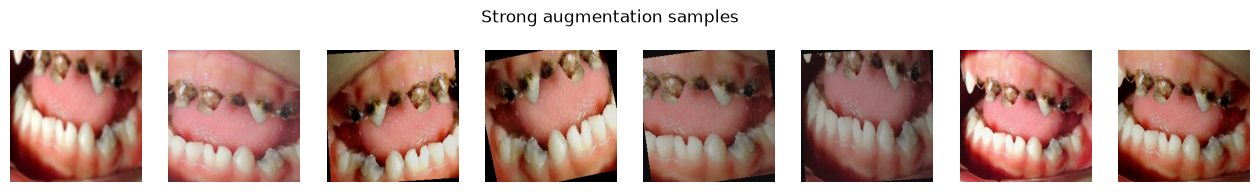

In [53]:
# Quick check of the augmentation pipeline: one training image under the strong transform
tf_s = make_tf("strong")
ex_path = kag[(kag.split == "train") & (kag.label == "caries")].cache.iloc[0]
imgs = [tf_s(Image.open(ex_path).convert("RGB")) for _ in range(8)]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
for a, t in zip(axes, imgs):
    a.imshow((t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)); a.axis("off")
fig.suptitle("Strong augmentation samples"); plt.show()

In [54]:
RECIPES = {
    "baseline":     dict(aug="light",  balanced=False, label_smoothing=0.0),   # A
    "balanced_aug": dict(aug="strong", balanced=True,  label_smoothing=0.1),   # B
}


def train_experiment(name, backbone, recipe, train_df, val_df):
    r = RECIPES[recipe]
    seed_everything()
    model = build_model(backbone).to(DEVICE)
    dl_tr = loader(train_df, make_tf(r["aug"]), shuffle=True, sampler=balanced_sampler(train_df) if r["balanced"] else None)
    dl_va = loader(val_df, make_tf("eval"))
    dl_vd = loader(val_df, make_tf("eval"), degrade=val_degrade_list(len(val_df)))
    opt = torch.optim.AdamW(model.parameters(), lr=BACKBONES[backbone]["lr"], weight_decay=CFG["weight_decay"])
    steps = CFG["epochs"] * len(dl_tr); warm = CFG["warmup_epochs"] * len(dl_tr)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=r["label_smoothing"])
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)   # only needed for fp16

    best, best_state, hist, bad = -1, None, [], 0
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
                loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        lv, yv = predict_logits(model, dl_va); ld, _ = predict_logits(model, dl_vd)
        mv = cls_metrics(yv, lv); mv["val_loss"] = F.cross_entropy(lv, torch.tensor(yv)).item()
        mv["deg_macro_f1"] = cls_metrics(yv, ld)["macro_f1"]
        mv["score"] = 0.5 * (mv["macro_f1"] + mv["deg_macro_f1"])
        hist.append(dict(epoch=ep, train_loss=tot / n, **mv, secs=time.time() - t0))
        print(f"{name} ep{ep:02d} train_loss {tot/n:.3f} | val_loss {mv['val_loss']:.3f} acc {mv['acc']:.3f} "
              f"bal_acc {mv['bal_acc']:.3f} macro_f1 {mv['macro_f1']:.3f} degraded_f1 {mv['deg_macro_f1']:.3f} "
              f"caries_rec {mv['recall_caries']:.2f} ({time.time()-t0:.0f}s)")
        if mv["score"] > best:
            best, bad = mv["score"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print("early stop"); break
    model.load_state_dict(best_state)
    torch.save({"state_dict": best_state, "backbone": backbone, "head": BACKBONES[backbone]["head"], "classes": CLASSES},
               WEIGHTS / f"exp_{name}.pt")
    h = pd.DataFrame(hist)
    return h, summarize_run(name, backbone, recipe, model, val_df, h)


def summarize_run(name, backbone, recipe, model, val_df, h):
    # Validation metrics + size/speed of a trained model. `h` is its training history (may be empty).
    lv, yv = predict_logits(model.to(DEVICE), loader(val_df, make_tf("eval")))
    ld, _ = predict_logits(model, loader(val_df, make_tf("eval"), degrade=val_degrade_list(len(val_df))))
    model.cpu(); torch.cuda.empty_cache()
    summary = dict(experiment=name, backbone=backbone, family=BACKBONES[backbone]["family"], recipe=recipe,
                   best_epoch=int(h.score.idxmax()) + 1 if len(h) else np.nan, epochs_run=len(h),
                   train_min=h.secs.sum() / 60 if len(h) else np.nan,
                   params_m=n_params_m(model), cpu_ms=cpu_latency_ms(model),
                   **{f"val_{k}": v for k, v in cls_metrics(yv, lv).items()},
                   val_degraded_macro_f1=cls_metrics(yv, ld)["macro_f1"])
    summary["val_score"] = 0.5 * (summary["val_macro_f1"] + summary["val_degraded_macro_f1"])
    return summary


def run_fingerprint(backbone, recipe, train_df, val_df):
    # Identifies a run by its data split and settings, so a finished run is only reused when nothing relevant changed.
    # Only used to warn when a reused run was trained under different settings; it never triggers retraining.
    key = dict(backbone=backbone, recipe=RECIPES[recipe], lr=BACKBONES[backbone]["lr"],
               train=sorted(train_df.md5), val=sorted(val_df.md5),
               **{k: CFG[k] for k in ["seed", "img_size", "epochs", "patience", "batch_size", "weight_decay", "warmup_epochs"]})
    return hashlib.md5(json.dumps(key, sort_keys=True).encode()).hexdigest()


def run_or_load(name, backbone, recipe, train_df, val_df):
    # Trains a run only if it has no checkpoint yet (or is listed in CFG["retrain"]); otherwise reuses it.
    fp = run_fingerprint(backbone, recipe, train_df, val_df)
    rec_path, ck_path = RUNS_DIR / f"{name}.json", WEIGHTS / f"exp_{name}.pt"
    force = CFG["retrain"] == "all" or name in CFG["retrain"]
    if ck_path.exists() and not force:
        if rec_path.exists():
            rec = json.loads(rec_path.read_text())
            if rec.get("fingerprint") not in (fp, "unknown"):
                print(f"  note: {name} was trained with a different split or settings than the current CFG "
                      f"(add it to CFG['retrain'] to retrain)")
            print(f"{name}: already trained, reusing (val score {rec['summary']['val_score']:.3f})")
            return pd.DataFrame(rec["history"]), rec["summary"]
        # Checkpoint but no record (e.g. the kernel stopped right after saving): rebuild the summary, don't retrain.
        print(f"{name}: checkpoint found without a run record; re-evaluating it on val instead of retraining")
        ck = torch.load(ck_path, map_location="cpu")
        assert ck["backbone"] == backbone, f"{ck_path.name} holds {ck['backbone']}, expected {backbone}"
        h, s, fp = pd.DataFrame(), summarize_run(name, backbone, recipe, load_run_model(name), val_df, pd.DataFrame()), "unknown"
    else:
        h, s = train_experiment(name, backbone, recipe, train_df, val_df)
    rec_path.write_text(json.dumps(dict(fingerprint=fp, summary=s, history=h.to_dict("records")), indent=1, default=float))
    return h, s


def load_run_model(name):
    ck = torch.load(WEIGHTS / f"exp_{name}.pt", map_location="cpu")
    m = build_model(ck["backbone"], pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval()

## 6. Train the experiments

Each run's best checkpoint is saved to `models/classifier/weights/Daniel/exp_<name>.pt` and its training history to `models/classifier/results/Daniel/runs/<name>.json`. **A run that already has a checkpoint is never retrained**: its saved results are reused, so re-running the notebook only trains backbones that are new in `CFG["sweep"]`, and an interrupted sweep resumes where it stopped. To retrain specific runs, list them in `CFG["retrain"]` (or set it to `"all"`). If the split or settings changed since a run was trained, a note is printed but the run is still reused.

The first 12 runs took about 65 minutes of training on an RTX 5070 Ti (ConvNeXt-Base, EfficientNetV2-S and ConvNeXt-Small were the slowest, at 7 to 8 minutes each); DenseNet-121 adds one more run. The first run of each backbone also downloads its ImageNet weights.

In [55]:
train_k = kag[(kag.split == "train")]
val_k = kag[(kag.split == "val") & kag.eval_rep]
test_k = kag[(kag.split == "test") & kag.eval_rep]
print(f"train files {len(train_k)} | val {len(val_k)} | test {len(test_k)}")

EXPERIMENTS = {f"A_baseline_{CFG['ablation_backbone']}": dict(backbone=CFG["ablation_backbone"], recipe="baseline")}
EXPERIMENTS.update({f"B_{b}": dict(backbone=b, recipe="balanced_aug") for b in CFG["sweep"]})
print(f"{len(EXPERIMENTS)} runs:", ", ".join(EXPERIMENTS))

histories, summaries = {}, []
for name, kw in EXPERIMENTS.items():
    histories[name], s = run_or_load(name, train_df=train_k, val_df=val_k, **kw)
    summaries.append(s)
    torch.cuda.empty_cache()

train files 3136 | val 320 | test 321
13 runs: A_baseline_convnext_tiny, B_convnext_tiny, B_convnext_small, B_convnext_base, B_efficientnet_b0, B_efficientnet_b3, B_efficientnet_v2_s, B_resnet50, B_regnet_y_3_2gf, B_densenet121, B_mobilenet_v3_large, B_swin_t, B_vit_b_16
A_baseline_convnext_tiny: already trained, reusing (val score 0.871)
B_convnext_tiny: already trained, reusing (val score 0.946)
B_convnext_small: already trained, reusing (val score 0.941)
B_convnext_base: already trained, reusing (val score 0.948)
B_efficientnet_b0: already trained, reusing (val score 0.943)
B_efficientnet_b3: already trained, reusing (val score 0.931)
B_efficientnet_v2_s: already trained, reusing (val score 0.936)
B_resnet50: already trained, reusing (val score 0.929)
B_regnet_y_3_2gf: already trained, reusing (val score 0.926)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\Dani/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 84.3MB/s]


B_densenet121 ep01 train_loss 1.147 | val_loss 0.402 acc 0.863 bal_acc 0.881 macro_f1 0.842 degraded_f1 0.804 caries_rec 0.85 (21s)
B_densenet121 ep02 train_loss 0.650 | val_loss 0.320 acc 0.912 bal_acc 0.879 macro_f1 0.873 degraded_f1 0.828 caries_rec 0.50 (18s)
B_densenet121 ep03 train_loss 0.584 | val_loss 0.298 acc 0.909 bal_acc 0.893 macro_f1 0.882 degraded_f1 0.871 caries_rec 0.62 (17s)
B_densenet121 ep04 train_loss 0.542 | val_loss 0.300 acc 0.912 bal_acc 0.886 macro_f1 0.881 degraded_f1 0.840 caries_rec 0.65 (18s)
B_densenet121 ep05 train_loss 0.534 | val_loss 0.282 acc 0.919 bal_acc 0.896 macro_f1 0.889 degraded_f1 0.865 caries_rec 0.73 (17s)
B_densenet121 ep06 train_loss 0.510 | val_loss 0.273 acc 0.947 bal_acc 0.923 macro_f1 0.926 degraded_f1 0.885 caries_rec 0.73 (16s)
B_densenet121 ep07 train_loss 0.501 | val_loss 0.302 acc 0.916 bal_acc 0.899 macro_f1 0.887 degraded_f1 0.849 caries_rec 0.58 (17s)
B_densenet121 ep08 train_loss 0.491 | val_loss 0.227 acc 0.944 bal_acc 0.928

### 6.1 Comparison on validation

The table is sorted by the selection score. `params_m` is the parameter count in millions; `cpu_ms` is the single-image latency on this machine's CPU (fp32, batch 1), which is what the app server pays per upload. The first row pair to read is **A vs B on ConvNeXt-Tiny** (effect of the training recipe), then the B rows against each other (effect of the architecture).

,family,params_m,cpu_ms,train_min,best_epoch,val_score,val_macro_f1,val_degraded_macro_f1,val_bal_acc,val_recall_caries,val_recall_normal,val_recall_mouth_ulcer
experiment,,,,,,,,,,,,
B_convnext_base,ConvNeXt,87.573,70.250,8.151,18,0.948,0.967,0.929,0.970,0.885,0.975,1.000
B_convnext_tiny,ConvNeXt,27.825,23.592,6.317,23,0.946,0.963,0.928,0.965,0.846,0.975,1.000
B_swin_t,Swin,27.524,27.489,5.750,15,0.945,0.969,0.921,0.967,0.846,0.975,1.000
B_efficientnet_b0,EfficientNet,4.015,9.351,5.095,14,0.943,0.961,0.925,0.959,0.885,0.950,0.935
B_convnext_small,ConvNeXt,49.459,44.368,7.302,24,0.941,0.961,0.921,0.966,0.885,0.975,1.000
B_efficientnet_v2_s,EfficientNet,20.185,26.662,7.705,22,0.936,0.948,0.924,0.951,0.769,0.975,1.000
B_vit_b_16,ViT,85.803,76.821,6.304,14,0.932,0.945,0.918,0.945,0.769,0.975,0.968
B_efficientnet_b3,EfficientNet,10.705,17.807,4.095,8,0.931,0.957,0.906,0.962,0.885,0.975,1.000
B_resnet50,ResNet,23.520,19.275,3.954,10,0.929,0.937,0.921,0.943,0.808,1.000,0.935


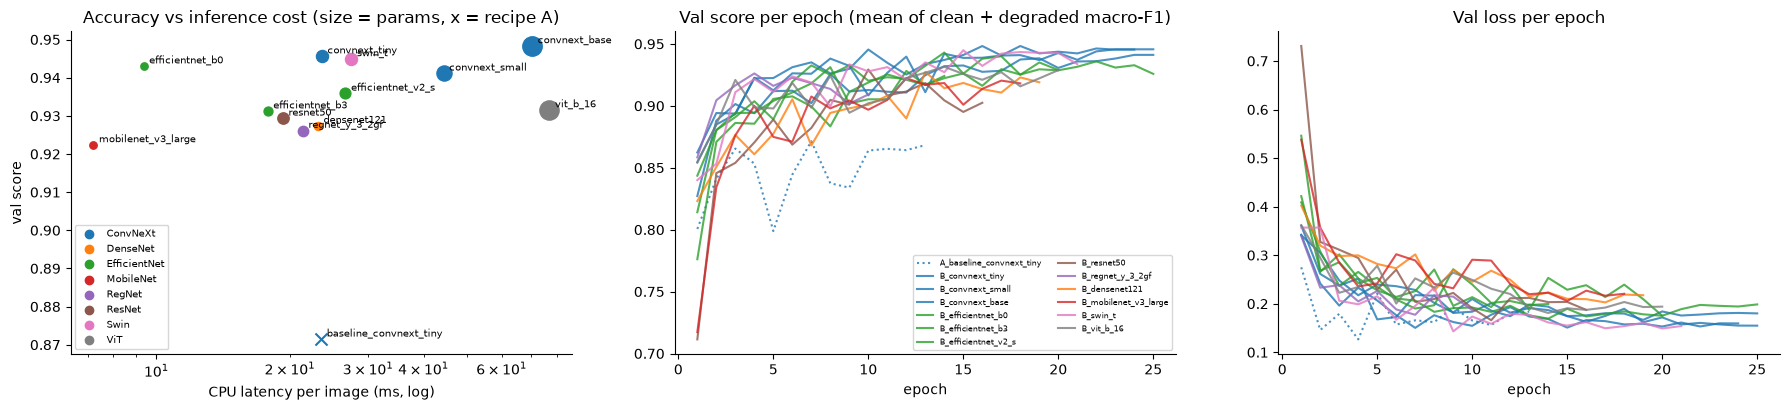

ConvNeXt size scaling (recipe B):


,params_m,cpu_ms,val_score,val_macro_f1,val_degraded_macro_f1
experiment,,,,,
B_convnext_tiny,27.825,23.592,0.946,0.963,0.928
B_convnext_small,49.459,44.368,0.941,0.961,0.921
B_convnext_base,87.573,70.250,0.948,0.967,0.929


In [56]:
comp = pd.DataFrame(summaries).set_index("experiment")
cols = ["family", "params_m", "cpu_ms", "train_min", "best_epoch", "val_score", "val_macro_f1", "val_degraded_macro_f1",
        "val_bal_acc", "val_recall_caries", "val_recall_normal", "val_recall_mouth_ulcer"]
display(comp.sort_values("val_score", ascending=False)[cols].round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
fams = sorted(comp.family.unique()); colors = dict(zip(fams, plt.cm.tab10.colors))
for name, r in comp.iterrows():
    ax[0].scatter(r.cpu_ms, r.val_score, s=20 + 2 * r.params_m, color=colors[r.family],
                  marker="x" if r.recipe == "baseline" else "o")
    ax[0].annotate(name.split("_", 1)[1], (r.cpu_ms, r.val_score), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set(xlabel="CPU latency per image (ms, log)", ylabel="val score",
                                   title="Accuracy vs inference cost (size = params, x = recipe A)")
for f in fams: ax[0].scatter([], [], color=colors[f], label=f)
ax[0].legend(fontsize=7)
for name, h in histories.items():
    if h.empty: continue                      # re-evaluated checkpoint with no saved training history
    style = ":" if name.startswith("A_") else "-"
    c = colors[comp.loc[name, "family"]]
    ax[1].plot(h.epoch, h.score, style, color=c, alpha=0.8, label=name)
    ax[2].plot(h.epoch, h.val_loss, style, color=c, alpha=0.8)
ax[1].set(title="Val score per epoch (mean of clean + degraded macro-F1)", xlabel="epoch"); ax[1].legend(fontsize=6, ncol=2)
ax[2].set(title="Val loss per epoch", xlabel="epoch")
plt.tight_layout(); plt.savefig(FIGS / "backbone_comparison.png", bbox_inches="tight"); plt.show()

conv = comp[comp.family == "ConvNeXt"].sort_values("params_m")
if len(conv) > 1:
    print("ConvNeXt size scaling (recipe B):")
    display(conv[conv.recipe == "balanced_aug"][["params_m", "cpu_ms", "val_score", "val_macro_f1", "val_degraded_macro_f1"]].round(3))

In [57]:
# Selection rule (declared in section 5): best val score; within tie_margin of it, the fastest model on CPU wins
ranked = comp.sort_values("val_score", ascending=False)
top = ranked.val_score.iloc[0]
tied = ranked[ranked.val_score >= top - CFG["tie_margin"]]
BEST = tied.cpu_ms.idxmin()
BEST_BACKBONE = comp.loc[BEST, "backbone"]
print(f"best val score {top:.3f} ({ranked.index[0]}); runs within {CFG['tie_margin']}:")
display(tied[["params_m", "cpu_ms", "val_score"]].round(3))
print("selected experiment:", BEST, "| backbone:", BEST_BACKBONE)
model = load_run_model(BEST)

best val score 0.948 (B_convnext_base); runs within 0.01:


,params_m,cpu_ms,val_score
experiment,,,
B_convnext_base,87.573,70.250,0.948
B_convnext_tiny,27.825,23.592,0.946
B_swin_t,27.524,27.489,0.945
B_efficientnet_b0,4.015,9.351,0.943
B_convnext_small,49.459,44.368,0.941


selected experiment: B_efficientnet_b0 | backbone: efficientnet_b0


## 7. Evaluation on the held-out Kaggle test set

The test set is de-duplicated (one image per photo group) and shares no photo group with training. The headline metrics are **macro-F1** and **balanced accuracy**; plain accuracy is shown for reference only, because it hides poor minority-class performance. 95% confidence intervals come from 2,000 bootstrap resamples of the test images. With only 25 to 40 unique test photos in the small classes, the intervals are wide and should be reported. Overlapping intervals between backbones mean the test set cannot separate them.

In [58]:
dl_te = loader(test_k, make_tf("eval"))
y_te = test_k.label.map(CLS2ID).values
test_logits = {}
for n in EXPERIMENTS:
    m = load_run_model(n); test_logits[n] = predict_logits(m, dl_te)[0]
    del m; torch.cuda.empty_cache()


def bootstrap_ci(y, logits, fn, n=2000, seed=0):
    rng = np.random.default_rng(seed); pred = logits.argmax(1).numpy(); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); vals.append(fn(y[i], pred[i]))
    return np.percentile(vals, [2.5, 97.5])


rows = []
for n, lg in test_logits.items():
    mt = cls_metrics(y_te, lg)
    lo, hi = bootstrap_ci(y_te, lg, lambda a, b: f1_score(a, b, average="macro", labels=range(NUM_CLASSES), zero_division=0))
    rows.append(dict(experiment=n, test_acc=mt["acc"], test_bal_acc=mt["bal_acc"], test_macro_f1=mt["macro_f1"],
                     macro_f1_95ci=f"[{lo:.3f}, {hi:.3f}]", test_recall_caries=mt["recall_caries"], test_recall_normal=mt["recall_normal"]))
test_table = pd.DataFrame(rows).set_index("experiment")
display(comp[["family", "params_m", "cpu_ms", "val_score"]].join(test_table).sort_values("val_score", ascending=False).round(3))
print("(All runs are shown for the comparison. Selection was made on validation only.)")

logits_best = test_logits[BEST]
pred_te = logits_best.argmax(1).numpy()
print(f"\nSelected model {BEST}: per-class report on the de-duplicated test set")
print(classification_report(y_te, pred_te, target_names=CLASSES, digits=3, zero_division=0))
print("one-vs-rest macro AUROC:", round(roc_auc_score(y_te, logits_best.softmax(1).numpy(), multi_class="ovr", average="macro"), 3))

,family,params_m,cpu_ms,val_score,test_acc,test_bal_acc,test_macro_f1,macro_f1_95ci,test_recall_caries,test_recall_normal
experiment,,,,,,,,,,
B_convnext_base,ConvNeXt,87.573,70.250,0.948,0.963,0.946,0.945,"[0.912, 0.972]",0.76,0.950
B_convnext_tiny,ConvNeXt,27.825,23.592,0.946,0.950,0.925,0.925,"[0.885, 0.958]",0.72,0.925
B_swin_t,Swin,27.524,27.489,0.945,0.953,0.929,0.928,"[0.890, 0.960]",0.72,0.950
B_efficientnet_b0,EfficientNet,4.015,9.351,0.943,0.956,0.941,0.936,"[0.900, 0.965]",0.80,0.950
B_convnext_small,ConvNeXt,49.459,44.368,0.941,0.956,0.938,0.935,"[0.901, 0.965]",0.72,0.950
B_efficientnet_v2_s,EfficientNet,20.185,26.662,0.936,0.950,0.916,0.919,"[0.878, 0.955]",0.60,0.950
B_vit_b_16,ViT,85.803,76.821,0.932,0.938,0.902,0.900,"[0.855, 0.939]",0.56,0.925
B_efficientnet_b3,EfficientNet,10.705,17.807,0.931,0.928,0.891,0.893,"[0.846, 0.934]",0.60,0.925
B_resnet50,ResNet,23.520,19.275,0.929,0.938,0.897,0.902,"[0.856, 0.942]",0.60,0.900


(All runs are shown for the comparison. Selection was made on validation only.)

Selected model B_efficientnet_b0: per-class report on the de-duplicated test set
                     precision    recall  f1-score   support

           calculus      0.821     1.000     0.901        32
             caries      0.870     0.800     0.833        25
         hypodontia      0.972     1.000     0.986        69
        mouth_ulcer      1.000     0.935     0.967        31
             normal      0.950     0.950     0.950        40
tooth_discoloration      1.000     0.960     0.979       124

           accuracy                          0.956       321
          macro avg      0.935     0.941     0.936       321
       weighted avg      0.960     0.956     0.957       321

one-vs-rest macro AUROC: 0.993


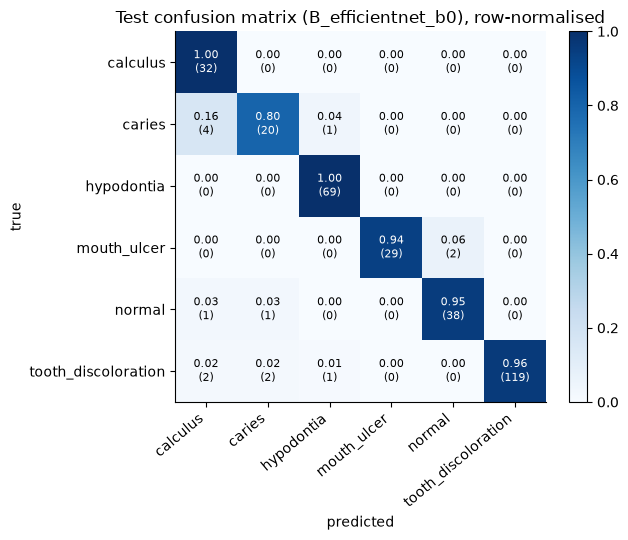

In [59]:
cm = confusion_matrix(y_te, pred_te, labels=range(NUM_CLASSES))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Test confusion matrix ({BEST}), row-normalised")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(FIGS / "confusion_matrix.png", bbox_inches="tight"); plt.show()

### 7.1 Calibration and abstention

The app turns probabilities into plain-language urgency, so a "90%" has to mean roughly 90%. We fit a single **temperature** on the validation logits, which does not change any prediction, and measure the expected calibration error (ECE) on test.

The model also needs a way to say *"I'm not sure, please see a dentist."* We choose the lowest confidence threshold (minimum 0.5) at which **validation** accuracy on accepted images reaches 95%, then report the coverage and accuracy that threshold gives on **test**.

temperature T = 0.592 | test ECE before 0.083 -> after 0.012
abstain below confidence 0.50: test coverage 99.7%, accuracy on accepted 95.6% (vs 95.6% overall); abstained images per true class:
mouth_ulcer    1


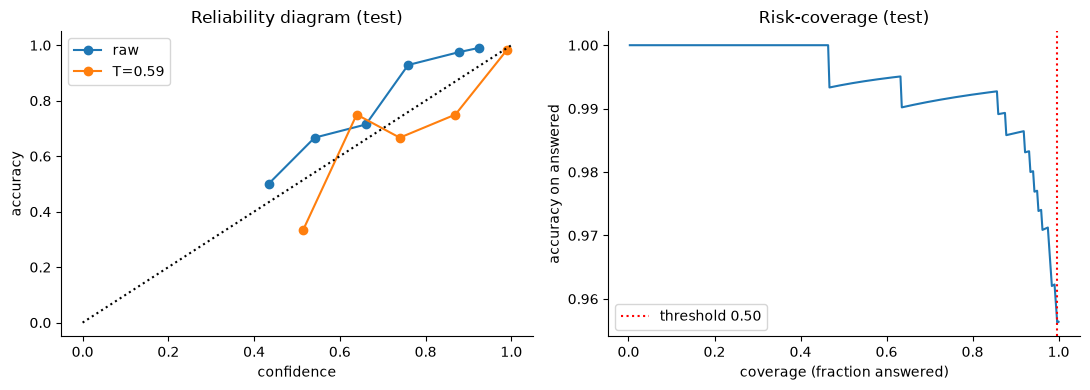

In [60]:
val_logits, y_va = predict_logits(model, loader(val_k, make_tf("eval")))


def fit_temperature(logits, y):
    t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([t], lr=0.1, max_iter=200)
    yt = torch.tensor(y)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(logits / t.exp(), yt); l.backward(); return l
    opt.step(closure)
    return float(t.exp())


def ece(probs, y, bins=15):
    conf, pred = probs.max(1); acc = (pred.numpy() == y)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf.numpy() > lo) & (conf.numpy() <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf.numpy()[m].mean())
    return e


T = fit_temperature(val_logits, y_va)
p_raw, p_cal = logits_best.softmax(1), (logits_best / T).softmax(1)
print(f"temperature T = {T:.3f} | test ECE before {ece(p_raw, y_te):.3f} -> after {ece(p_cal, y_te):.3f}")

# abstention threshold from validation
pv = (val_logits / T).softmax(1); cv, predv = pv.max(1); okv = predv.numpy() == y_va
THRESH = None
for t in np.linspace(CFG["min_abstain_conf"], 0.99, 50):
    m = cv.numpy() >= t
    if m.mean() >= 0.5 and okv[m].mean() >= CFG["target_selective_accuracy"]:
        THRESH = float(t); break
if THRESH is None:
    print("target selective accuracy not reachable at >=50% coverage; using the floor")
    THRESH = CFG["min_abstain_conf"]
ct, predt = p_cal.max(1); okt = predt.numpy() == y_te; acc_m = ct.numpy() >= THRESH
print(f"abstain below confidence {THRESH:.2f}: test coverage {acc_m.mean():.1%}, accuracy on accepted {okt[acc_m].mean():.1%} "
      f"(vs {okt.mean():.1%} overall); abstained images per true class:")
print(pd.Series(np.array(CLASSES)[y_te[~acc_m]]).value_counts().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for p, lab in [(p_raw, "raw"), (p_cal, f"T={T:.2f}")]:
    c, pr = p.max(1); edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c.numpy() > lo) & (c.numpy() <= hi)
        if m.sum() >= 3: xs.append(c.numpy()[m].mean()); ys.append((pr.numpy()[m] == y_te[m]).mean())
    ax[0].plot(xs, ys, "o-", label=lab)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="confidence", ylabel="accuracy", title="Reliability diagram (test)"); ax[0].legend()
order_ = np.argsort(-ct.numpy()); cov = np.arange(1, len(order_) + 1) / len(order_)
ax[1].plot(cov, np.cumsum(okt[order_]) / np.arange(1, len(order_) + 1))
ax[1].axvline(acc_m.mean(), ls=":", c="r", label=f"threshold {THRESH:.2f}")
ax[1].set(xlabel="coverage (fraction answered)", ylabel="accuracy on answered", title="Risk-coverage (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIGS / "calibration_abstention.png", bbox_inches="tight"); plt.show()

### 7.2 Robustness to poor photos and the resolution shortcut

Patients will upload dark, blurry, low-resolution phone photos. We re-run the test set under controlled degradations for every run. The **low-res** case also probes the Normal-class shortcut: if Normal recall collapses when Normal photos are reduced to web-image quality, the model was partly relying on resolution rather than anatomy.

In [61]:
rob_all = []
for n in EXPERIMENTS:
    m = load_run_model(n); base = None
    for dname, fn in DEGRADATIONS.items():
        lg, _ = predict_logits(m, loader(test_k, make_tf("eval"), degrade=fn))
        mt = cls_metrics(y_te, lg); pr = lg.argmax(1).numpy(); base = pr if base is None else base
        rob_all.append(dict(experiment=n, condition=dname, macro_f1=mt["macro_f1"], recall_normal=mt["recall_normal"],
                            recall_caries=mt["recall_caries"], changed_vs_original=(pr != base).mean()))
    del m; torch.cuda.empty_cache()
rob_df = pd.DataFrame(rob_all)
print("Test macro-F1 under degraded photos")
display(rob_df.pivot(index="experiment", columns="condition", values="macro_f1")[list(DEGRADATIONS)].round(3))
print("Normal-class recall under degraded photos (resolution-shortcut probe)")
display(rob_df.pivot(index="experiment", columns="condition", values="recall_normal")[list(DEGRADATIONS)].round(3))
rob = rob_df[rob_df.experiment == BEST].drop(columns="experiment").to_dict("records")

Test macro-F1 under degraded photos


condition,original,low-res 160px + JPEG60,dark (x0.5),bright (x1.6),blur (r=2),JPEG q=20
experiment,,,,,,
A_baseline_convnext_tiny,0.915,0.553,0.910,0.825,0.848,0.708
B_convnext_base,0.945,0.878,0.938,0.931,0.918,0.907
B_convnext_small,0.935,0.878,0.931,0.923,0.905,0.919
B_convnext_tiny,0.925,0.886,0.920,0.890,0.928,0.934
B_densenet121,0.924,0.822,0.888,0.875,0.888,0.894
B_efficientnet_b0,0.936,0.836,0.931,0.885,0.887,0.902
B_efficientnet_b3,0.893,0.849,0.897,0.868,0.897,0.900
B_efficientnet_v2_s,0.919,0.878,0.933,0.879,0.892,0.915
B_mobilenet_v3_large,0.905,0.860,0.895,0.901,0.893,0.907


Normal-class recall under degraded photos (resolution-shortcut probe)


condition,original,low-res 160px + JPEG60,dark (x0.5),bright (x1.6),blur (r=2),JPEG q=20
experiment,,,,,,
A_baseline_convnext_tiny,0.925,0.025,0.950,0.875,0.950,0.275
B_convnext_base,0.950,0.900,0.925,0.925,0.950,0.925
B_convnext_small,0.950,0.900,0.950,0.950,0.950,0.925
B_convnext_tiny,0.925,0.875,0.925,0.950,0.950,0.950
B_densenet121,0.950,0.925,0.950,0.950,0.950,0.950
B_efficientnet_b0,0.950,0.925,0.950,0.925,0.950,0.950
B_efficientnet_b3,0.925,0.900,0.925,0.925,0.950,0.925
B_efficientnet_v2_s,0.950,0.925,0.950,0.950,0.950,0.950
B_mobilenet_v3_large,0.950,0.925,0.950,0.950,0.950,0.950


### 7.3 Explainability: Grad-CAM

Grad-CAM shows which pixels drove the prediction of the selected model. This is useful both for the report (transparency) and for spotting shortcuts, such as a model that looks at lips, background or watermarks instead of teeth. For ViT the token grid is reshaped to a 14×14 map, so its maps are coarser than the CNNs'.

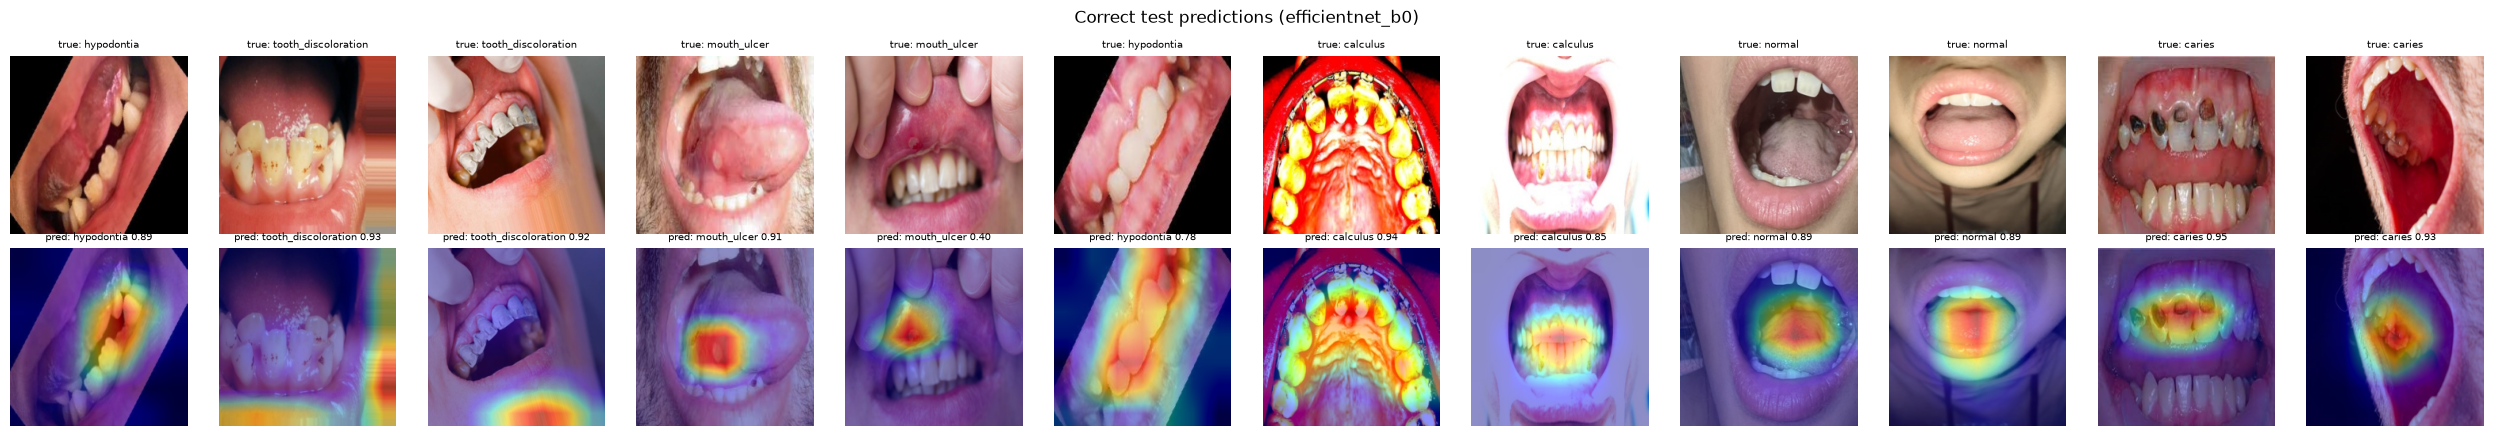

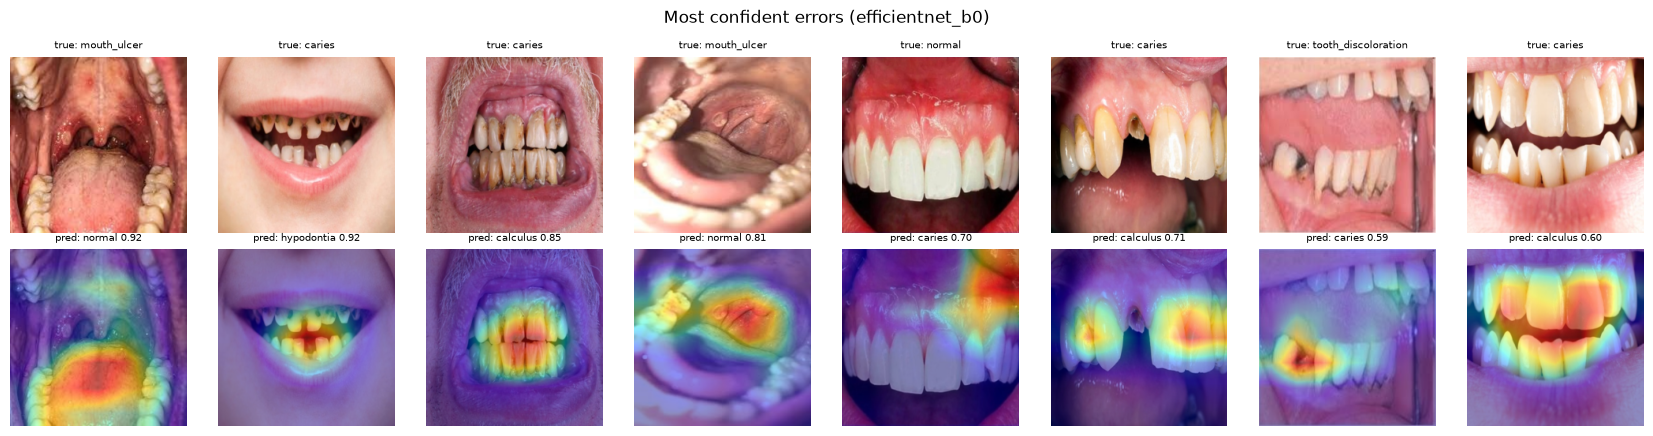

In [62]:
def _to_map(t):
    # CNN / Swin activations are already (B, C, H, W); ViT tokens (B, 1 + N, D) become (B, D, sqrt N, sqrt N).
    if t.ndim == 3:
        t = t[:, 1:, :]; s = int(round(t.shape[1] ** 0.5))
        t = t.reshape(t.shape[0], s, s, t.shape[2]).permute(0, 3, 1, 2)
    return t


def gradcam(model, x, cls=None):
    store = {}
    layer = cam_layer(model)
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    logits = model(x)
    cls = logits.argmax(1) if cls is None else cls
    logits.gather(1, cls[:, None]).sum().backward()
    h.remove()
    a, g = _to_map(store["a"]), _to_map(store["g"])
    w = g.mean((2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu(), logits.detach().softmax(1).cpu()


def show_cams(df, title, n=8):
    df = df.head(n)
    x = torch.stack([make_tf("eval")(Image.open(p).convert("RGB")) for p in df.cache]).to(DEVICE)
    cams, probs = gradcam(model.float(), x)
    fig, axes = plt.subplots(2, len(df), figsize=(2.1 * len(df), 4.4))
    axes = np.array(axes).reshape(2, -1)
    for i in range(len(df)):
        img = (x[i].cpu().permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()
        axes[0, i].imshow(img); axes[0, i].set_title(f"true: {df.label.iloc[i]}", fontsize=7)
        axes[1, i].imshow(img); axes[1, i].imshow(cams[i], cmap="jet", alpha=0.45)
        k = probs[i].argmax().item(); axes[1, i].set_title(f"pred: {CLASSES[k]} {probs[i, k]:.2f}", fontsize=7)
        for a in axes[:, i]: a.axis("off")
    fig.suptitle(f"{title} ({BEST_BACKBONE})"); plt.tight_layout()
    plt.savefig(FIGS / f"gradcam_{title.split()[0].lower()}.png", bbox_inches="tight"); plt.show()


te = test_k.assign(pred=np.array(CLASSES)[pred_te], conf=p_cal.max(1).values.numpy())
show_cams(te[te.pred == te.label].sample(frac=1, random_state=0).groupby("label").head(2),
          "Correct test predictions", n=12)
wrong = te[te.pred != te.label].sort_values("conf", ascending=False)
if len(wrong):
    show_cams(wrong, "Most confident errors", n=min(8, len(wrong)))

## 8. Save the model and results

In [63]:
def predict_image(image_path, model=model, T=T, thresh=THRESH):
    # Same contract as models/classifier/src/predict.py: ids/names from shared/conditions.yaml.
    im = load_rgb(image_path, CFG["cache_max_side"])
    x = make_tf("eval")(im)[None].to(DEVICE)
    with torch.no_grad():
        probs = (model.float().eval()(x) / T).softmax(1)[0].cpu().numpy()
    order = probs.argsort()[::-1]
    k = int(order[0])
    return {"class_id": k, "class_name": CLASSES[k], "display_name": DISPLAY[CLASSES[k]], "confidence": float(probs[k]),
            "abstain": bool(probs[k] < thresh),
            "top2": [(CLASSES[i], round(float(probs[i]), 3)) for i in order[:2]],
            "probs": {c: round(float(p), 4) for c, p in zip(CLASSES, probs)}}


for p in test_k.groupby("label").head(1).path:
    r = predict_image(p); print(f"{Path(p).parent.name:>20} -> {r['class_name']:<20} conf {r['confidence']:.2f} abstain={r['abstain']} top2={r['top2']}")

            Calculus -> calculus             conf 0.99 abstain=False top2=[('calculus', 0.993), ('caries', 0.002)]
              caries -> calculus             conf 0.90 abstain=False top2=[('calculus', 0.905), ('hypodontia', 0.085)]
          Hypodontia -> hypodontia           conf 0.98 abstain=False top2=[('hypodontia', 0.981), ('calculus', 0.01)]
         Mouth ulcer -> mouth_ulcer          conf 1.00 abstain=False top2=[('mouth_ulcer', 0.996), ('tooth_discoloration', 0.001)]
              Normal -> normal               conf 0.99 abstain=False top2=[('normal', 0.992), ('hypodontia', 0.002)]
 tooth discoloration -> tooth_discoloration  conf 0.99 abstain=False top2=[('tooth_discoloration', 0.993), ('normal', 0.003)]


In [64]:
final_test = cls_metrics(y_te, logits_best)
ckpt = dict(
    state_dict={k: v.cpu() for k, v in model.state_dict().items()},
    backbone=BEST_BACKBONE, head=BACKBONES[BEST_BACKBONE]["head"],
    classes=CLASSES, class_ids=list(range(NUM_CLASSES)), display_names=DISPLAY,
    img_size=S, mean=MEAN, std=STD, preprocessing="EXIF-transpose, RGB, thumbnail to 384px, resize (squash) to 224x224, ImageNet normalise",
    temperature=T, abstain_threshold=THRESH, experiment=BEST, config=CFG,
    val_metrics=comp.loc[BEST].to_dict(), test_metrics=final_test,
    created=datetime.datetime.now().isoformat(timespec="seconds"),
    notes=("Screening and education aid only, not a diagnosis. Trained on non-Singapore web/clinical photos (Kaggle). "
           "Cannot detect gum disease (not a class); 'normal' means none of the 5 screened conditions was seen. "
           "Show top-2 conditions; if abstain is True ask for a retake or recommend a dental visit."),
)
torch.save(ckpt, WEIGHTS / "best.pt")

pd.DataFrame(summaries).merge(test_table.reset_index(), on="experiment").assign(
    date=datetime.date.today().isoformat(), selected=lambda d: d.experiment == BEST
).to_csv(RESULTS / "experiments.csv", index=False)
json.dump(dict(experiment=BEST, backbone=BEST_BACKBONE, temperature=T, abstain_threshold=THRESH,
               test={k: float(v) for k, v in final_test.items()},
               test_macro_f1_95ci=test_table.loc[BEST, "macro_f1_95ci"],
               robustness=rob, n_test=int(len(test_k)), n_val=int(len(val_k))),
          open(RESULTS / "test_metrics.json", "w"), indent=2, default=float)
print("saved:", WEIGHTS / "best.pt", "|", RESULTS / "experiments.csv", "|", RESULTS / "test_metrics.json", "|", FIGS)

saved: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\weights\Daniel\best.pt | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\experiments.csv | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\test_metrics.json | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\Daniel\figures


## 9. Results at a glance

The table below is generated from this run, so it always matches the saved files. Exact numbers vary slightly between runs (GPU non-determinism); `models/classifier/results/Daniel/experiments.csv` and `test_metrics.json` hold the latest values.

**Questions the table answers for the report**
1. **Training recipe.** Does balancing + strong augmentation (B) beat the naive baseline (A) on ConvNeXt-Tiny, especially on caries recall and on Normal recall for low-res photos (the resolution shortcut)?
2. **Model size.** Do ConvNeXt-Small and -Base improve on Tiny, or does the extra capacity not pay off with ~1,000 unique training photos? Compare the gain against the bootstrap CI width.
3. **Architecture.** How do the transformers (Swin-T, ViT-B/16) compare with CNNs of similar size? ViT is expected to suffer most from the small dataset.
4. **Deployment cost.** How much accuracy is lost by the phone-class models (MobileNetV3, EfficientNet-B0) relative to the selected model?

One finding does not depend on the model: **duplicates were the biggest data issue.** A random split would have leaked a copy of a training photo into about half of the test images (section 3). All numbers here come from a group-disjoint, de-duplicated test set.

In [65]:
lowres_ = (rob_df[rob_df.condition == "low-res 160px + JPEG60"].set_index("experiment")[["macro_f1", "recall_normal"]]
           .rename(columns={"macro_f1": "lowres_macro_f1", "recall_normal": "lowres_recall_normal"}))
glance = (comp[["family", "recipe", "params_m", "cpu_ms", "val_score"]]
          .join(test_table[["test_macro_f1", "macro_f1_95ci", "test_bal_acc", "test_recall_caries"]]).join(lowres_)
          .sort_values("val_score", ascending=False))
glance.insert(0, "selected", np.where(glance.index == BEST, "<<", ""))
display(glance.round(3))

a_name, b_name = f"A_baseline_{CFG['ablation_backbone']}", f"B_{CFG['ablation_backbone']}"
lines = [f"- **Selected:** `{BEST}` ({comp.loc[BEST, 'params_m']:.0f}M params, {comp.loc[BEST, 'cpu_ms']:.0f} ms/image on CPU): "
         f"test macro-F1 {test_table.loc[BEST, 'test_macro_f1']:.3f} {test_table.loc[BEST, 'macro_f1_95ci']}, "
         f"caries recall {test_table.loc[BEST, 'test_recall_caries']:.2f}."]
if a_name in comp.index and b_name in comp.index:
    lines.append(f"- **Recipe (A to B on {CFG['ablation_backbone']}):** test macro-F1 {test_table.loc[a_name, 'test_macro_f1']:.3f} to "
                 f"{test_table.loc[b_name, 'test_macro_f1']:.3f}; low-res Normal recall {lowres_.loc[a_name, 'lowres_recall_normal']:.2f} to "
                 f"{lowres_.loc[b_name, 'lowres_recall_normal']:.2f}.")
b_runs = glance[glance.recipe == "balanced_aug"]
if len(b_runs):
    lines.append(f"- **Backbones (recipe B):** val score ranges from {b_runs.val_score.min():.3f} (`{b_runs.val_score.idxmin()}`) "
                 f"to {b_runs.val_score.max():.3f} (`{b_runs.val_score.idxmax()}`).")
    fastest = b_runs.cpu_ms.idxmin()
    lines.append(f"- **Cheapest model:** `{fastest}` ({b_runs.loc[fastest, 'cpu_ms']:.0f} ms/image), test macro-F1 "
                 f"{b_runs.loc[fastest, 'test_macro_f1']:.3f}.")
lines.append(f"- **Calibration:** temperature T = {T:.2f}; abstaining below {THRESH:.2f} answers {acc_m.mean():.1%} of test photos "
             f"at {okt[acc_m].mean():.1%} accuracy.")
display(Markdown("\n".join(lines)))

,selected,family,recipe,params_m,cpu_ms,val_score,test_macro_f1,macro_f1_95ci,test_bal_acc,test_recall_caries,lowres_macro_f1,lowres_recall_normal
experiment,,,,,,,,,,,,
B_convnext_base,,ConvNeXt,balanced_aug,87.573,70.250,0.948,0.945,"[0.912, 0.972]",0.946,0.76,0.878,0.900
B_convnext_tiny,,ConvNeXt,balanced_aug,27.825,23.592,0.946,0.925,"[0.885, 0.958]",0.925,0.72,0.886,0.875
B_swin_t,,Swin,balanced_aug,27.524,27.489,0.945,0.928,"[0.890, 0.960]",0.929,0.72,0.870,0.925
B_efficientnet_b0,<<,EfficientNet,balanced_aug,4.015,9.351,0.943,0.936,"[0.900, 0.965]",0.941,0.80,0.836,0.925
B_convnext_small,,ConvNeXt,balanced_aug,49.459,44.368,0.941,0.935,"[0.901, 0.965]",0.938,0.72,0.878,0.900
B_efficientnet_v2_s,,EfficientNet,balanced_aug,20.185,26.662,0.936,0.919,"[0.878, 0.955]",0.916,0.60,0.878,0.925
B_vit_b_16,,ViT,balanced_aug,85.803,76.821,0.932,0.900,"[0.855, 0.939]",0.902,0.56,0.820,0.900
B_efficientnet_b3,,EfficientNet,balanced_aug,10.705,17.807,0.931,0.893,"[0.846, 0.934]",0.891,0.60,0.849,0.900
B_resnet50,,ResNet,balanced_aug,23.520,19.275,0.929,0.902,"[0.856, 0.942]",0.897,0.60,0.806,0.750


- **Selected:** `B_efficientnet_b0` (4M params, 9 ms/image on CPU): test macro-F1 0.936 [0.900, 0.965], caries recall 0.80.
- **Recipe (A to B on convnext_tiny):** test macro-F1 0.915 to 0.925; low-res Normal recall 0.03 to 0.88.
- **Backbones (recipe B):** val score ranges from 0.922 (`B_mobilenet_v3_large`) to 0.948 (`B_convnext_base`).
- **Cheapest model:** `B_mobilenet_v3_large` (7 ms/image), test macro-F1 0.905.
- **Calibration:** temperature T = 0.59; abstaining below 0.50 answers 99.7% of test photos at 95.6% accuracy.

## 10. Limitations and responsible-AI notes (for the report)

**What the numbers do and do not show**
- Test metrics are on a *de-duplicated, group-disjoint* split, so they are lower than numbers from a naive random split but honest. With ~30 to 40 unique test photos in the small classes, per-class recall moves several points from one image. Quote the bootstrap CI.
- **Model comparison.** Every backbone was trained once with one seed and one learning rate per family. Differences smaller than the bootstrap CI (or the 0.01 tie margin on val) should not be reported as one architecture being better. A fair claim needs several seeds per backbone.
- **No external validation.** Only Kaggle data is used, so all numbers measure performance on photos from the same sources the model trained on. Kaggle images are mostly web images, often textbook-severe cases. Early, subtle disease, the case the brief cares about most, is under-represented, so real-world sensitivity for early lesions and on clinical or phone photos is likely **lower** than measured here.

**Dataset issues that cannot be fully fixed by modelling**
- **No gum disease class.** Up to 90% of Singapore adults have some gum disease and the model cannot see it. The app must never say "your mouth is healthy". It should say "none of the five screened conditions was detected" and always prompt for a check-up, especially if gums bleed.
- **Single label per image.** Conflicting duplicates show that many photos contain several conditions. The app should present the top two probabilities and avoid presenting the argmax as *the* problem.
- **Not Singapore patients; no demographic metadata.** We cannot measure performance by age, ethnicity or skin/gum pigmentation, and with Kaggle data alone we cannot test for population shift at all. Before real use, a Singapore validation set (for example through the Oral Link collaboration) with consented demographic fields is needed.
- **Source confounding.** The Normal class comes from different cameras. The resolution test in 7.2 shows how much this matters, and it cannot be removed completely without new, consistently captured normal photos.
- **Hypodontia** (congenitally missing teeth) is a developmental condition, mostly photographed in children. A photo of an adult with an extracted tooth may be labelled hypodontia, so the app should phrase this as "gap / missing tooth".

**Safety, privacy and transparency in the app**
- Low-confidence results (`abstain=True`) or poor-quality photos (the `quality_check` model) should lead to a retake or a dentist referral, never a guess.
- Emergency red flags (facial swelling, uncontrolled bleeding, trauma) must be screened *before* the classifier and routed to 995 / A&E, regardless of the model output.
- PDPA: classify in memory, do not retain uploaded photos without explicit consent, and never use them for retraining without separate consent.
- Grad-CAM overlays can be shown to the user ("the model looked here") to make the screening less of a black box.